# UCS420 – Cognitive Computing
## Lab Assignment 10: NLP using Python-II
**Topic:** Feature extraction from text, sentiment analysis and text generation

**Name:** Abhinandan Goyal  |  **Roll No:** 1024170176

In [1]:
import warnings, os
warnings.filterwarnings('ignore')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import nltk
for pkg in ['punkt','punkt_tab','stopwords','wordnet','omw-1.4']:
    nltk.download(pkg, quiet=True)
print('NLTK resources ready')

NLTK resources ready


## Q1. Text preprocessing on my own paragraph (topic: Cricket)

In [2]:
paragraph = ("Cricket is more than just a sport in India, it's an emotion that connects millions of people. "
             "I love watching India play big tournaments with my family and friends, cheering for every boundary and wicket. "
             "The game teaches patience, because a batter has to wait for the right ball before playing a big shot. "
             "Playing gully cricket with college friends taught me teamwork and how to handle pressure. "
             "T20 leagues like the IPL have made the game faster and more exciting than ever before. "
             "Whether it is a long Test match or a quick evening game, cricket always brings people together.")
print(paragraph)

Cricket is more than just a sport in India, it's an emotion that connects millions of people. I love watching India play big tournaments with my family and friends, cheering for every boundary and wicket. The game teaches patience, because a batter has to wait for the right ball before playing a big shot. Playing gully cricket with college friends taught me teamwork and how to handle pressure. T20 leagues like the IPL have made the game faster and more exciting than ever before. Whether it is a long Test match or a quick evening game, cricket always brings people together.


### 1. Lowercase + remove punctuation using `re`

In [3]:
import re
lower_text = paragraph.lower()
clean_text = re.sub(r"[^\w\s]", "", lower_text)     # remove everything except word chars and whitespace
print(clean_text)

cricket is more than just a sport in india its an emotion that connects millions of people i love watching india play big tournaments with my family and friends cheering for every boundary and wicket the game teaches patience because a batter has to wait for the right ball before playing a big shot playing gully cricket with college friends taught me teamwork and how to handle pressure t20 leagues like the ipl have made the game faster and more exciting than ever before whether it is a long test match or a quick evening game cricket always brings people together


### 2. Tokenize into sentences and words

In [4]:
from nltk.tokenize import sent_tokenize, word_tokenize
sentences = sent_tokenize(paragraph)          # sentence tokenizing is done on the original text (needs punctuation)
print("Number of sentences:", len(sentences))
for i, s in enumerate(sentences, 1):
    print(f"{i}. {s}")

words_clean = word_tokenize(clean_text)       # words from the cleaned text
print("\nNumber of words:", len(words_clean))
print(words_clean)

Number of sentences: 6
1. Cricket is more than just a sport in India, it's an emotion that connects millions of people.
2. I love watching India play big tournaments with my family and friends, cheering for every boundary and wicket.
3. The game teaches patience, because a batter has to wait for the right ball before playing a big shot.
4. Playing gully cricket with college friends taught me teamwork and how to handle pressure.
5. T20 leagues like the IPL have made the game faster and more exciting than ever before.
6. Whether it is a long Test match or a quick evening game, cricket always brings people together.

Number of words: 101
['cricket', 'is', 'more', 'than', 'just', 'a', 'sport', 'in', 'india', 'its', 'an', 'emotion', 'that', 'connects', 'millions', 'of', 'people', 'i', 'love', 'watching', 'india', 'play', 'big', 'tournaments', 'with', 'my', 'family', 'and', 'friends', 'cheering', 'for', 'every', 'boundary', 'and', 'wicket', 'the', 'game', 'teaches', 'patience', 'because', 'a

### 3. `split()` vs `word_tokenize()`

In [5]:
split_tokens = paragraph.split()
nltk_tokens  = word_tokenize(paragraph)
print("split() tokens        :", len(split_tokens))
print("word_tokenize() tokens:", len(nltk_tokens))
print("\nFirst 15 with split()        :", split_tokens[:15])
print("First 15 with word_tokenize():", nltk_tokens[:15])

only_split = [t for t in split_tokens if t not in nltk_tokens]
only_nltk  = [t for t in nltk_tokens  if t not in split_tokens]
print("\nTokens produced only by split()        :", only_split)
print("Tokens produced only by word_tokenize():", only_nltk)

split() tokens        : 101
word_tokenize() tokens: 112

First 15 with split()        : ['Cricket', 'is', 'more', 'than', 'just', 'a', 'sport', 'in', 'India,', "it's", 'an', 'emotion', 'that', 'connects', 'millions']
First 15 with word_tokenize(): ['Cricket', 'is', 'more', 'than', 'just', 'a', 'sport', 'in', 'India', ',', 'it', "'s", 'an', 'emotion', 'that']

Tokens produced only by split()        : ['India,', "it's", 'people.', 'friends,', 'wicket.', 'patience,', 'shot.', 'pressure.', 'before.', 'game,', 'together.']
Tokens produced only by word_tokenize(): [',', "'s", '.', ',', 'wicket', '.', 'patience', ',', 'shot', '.', 'pressure', '.', '.', ',', 'together', '.']


**Comparison**

| | `split()` | `word_tokenize()` |
|---|---|---|
| Splits on | only whitespace | whitespace + punctuation + contractions (language-aware rules) |
| Punctuation | stays attached to words (`India,` `boundary`) | separated as their own tokens (`India` `,`) |
| Contractions | `it's` stays as one token | `it's` → `it` + `'s` |
| Speed / dependency | very fast, pure Python | slower, needs NLTK + punkt data |
| Best for | quick and simple splitting of already-clean text | real NLP pipelines where punctuation must be handled properly |

So `split()` gives tokens like `"India,"` and `"wicket."` which would be counted as different from `"india"` and `"wicket"`, while `word_tokenize()` gives cleaner tokens (and extra punctuation tokens that we can filter).

### 4. Remove stopwords (NLTK)

In [6]:
from nltk.corpus import stopwords
stop_words = set(stopwords.words('english'))
filtered = [w for w in words_clean if w not in stop_words]
print("Before:", len(words_clean), " After:", len(filtered))
print(filtered)

Before: 101  After: 59
['cricket', 'sport', 'india', 'emotion', 'connects', 'millions', 'people', 'love', 'watching', 'india', 'play', 'big', 'tournaments', 'family', 'friends', 'cheering', 'every', 'boundary', 'wicket', 'game', 'teaches', 'patience', 'batter', 'wait', 'right', 'ball', 'playing', 'big', 'shot', 'playing', 'gully', 'cricket', 'college', 'friends', 'taught', 'teamwork', 'handle', 'pressure', 't20', 'leagues', 'like', 'ipl', 'made', 'game', 'faster', 'exciting', 'ever', 'whether', 'long', 'test', 'match', 'quick', 'evening', 'game', 'cricket', 'always', 'brings', 'people', 'together']


### 5. Word frequency distribution (excluding stopwords)

[('cricket', 3), ('game', 3), ('india', 2), ('people', 2), ('big', 2), ('friends', 2), ('playing', 2), ('sport', 1), ('emotion', 1), ('connects', 1), ('millions', 1), ('love', 1), ('watching', 1), ('play', 1), ('tournaments', 1)]


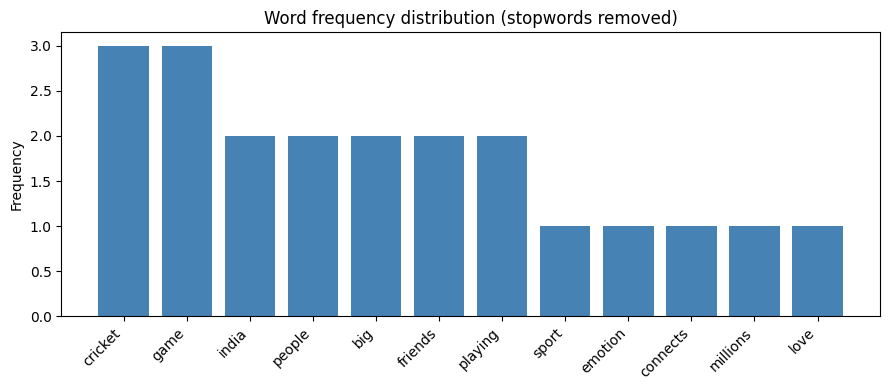

In [7]:
from nltk import FreqDist
import matplotlib.pyplot as plt
fd = FreqDist(filtered)
print(fd.most_common(15))

top = fd.most_common(12)
plt.figure(figsize=(9,4))
plt.bar([w for w,_ in top], [c for _,c in top], color="steelblue")
plt.xticks(rotation=45, ha="right")
plt.title("Word frequency distribution (stopwords removed)")
plt.ylabel("Frequency"); plt.tight_layout(); plt.show()

## Q2. Alphabet-only words, stemming and lemmatization (same paragraph)

### 1. Extract alphabet-only words using `re.findall()`

In [8]:
alpha_words = re.findall(r"[a-zA-Z]+", paragraph.lower())
print(len(alpha_words), alpha_words)

102 ['cricket', 'is', 'more', 'than', 'just', 'a', 'sport', 'in', 'india', 'it', 's', 'an', 'emotion', 'that', 'connects', 'millions', 'of', 'people', 'i', 'love', 'watching', 'india', 'play', 'big', 'tournaments', 'with', 'my', 'family', 'and', 'friends', 'cheering', 'for', 'every', 'boundary', 'and', 'wicket', 'the', 'game', 'teaches', 'patience', 'because', 'a', 'batter', 'has', 'to', 'wait', 'for', 'the', 'right', 'ball', 'before', 'playing', 'a', 'big', 'shot', 'playing', 'gully', 'cricket', 'with', 'college', 'friends', 'taught', 'me', 'teamwork', 'and', 'how', 'to', 'handle', 'pressure', 't', 'leagues', 'like', 'the', 'ipl', 'have', 'made', 'the', 'game', 'faster', 'and', 'more', 'exciting', 'than', 'ever', 'before', 'whether', 'it', 'is', 'a', 'long', 'test', 'match', 'or', 'a', 'quick', 'evening', 'game', 'cricket', 'always', 'brings', 'people', 'together']


### 2. Remove stopwords

In [9]:
q2_words = [w for w in alpha_words if w not in stop_words]
print(len(q2_words), q2_words)

58 ['cricket', 'sport', 'india', 'emotion', 'connects', 'millions', 'people', 'love', 'watching', 'india', 'play', 'big', 'tournaments', 'family', 'friends', 'cheering', 'every', 'boundary', 'wicket', 'game', 'teaches', 'patience', 'batter', 'wait', 'right', 'ball', 'playing', 'big', 'shot', 'playing', 'gully', 'cricket', 'college', 'friends', 'taught', 'teamwork', 'handle', 'pressure', 'leagues', 'like', 'ipl', 'made', 'game', 'faster', 'exciting', 'ever', 'whether', 'long', 'test', 'match', 'quick', 'evening', 'game', 'cricket', 'always', 'brings', 'people', 'together']


### 3. Stemming with `PorterStemmer`

In [10]:
from nltk.stem import PorterStemmer
ps = PorterStemmer()
stemmed = [ps.stem(w) for w in q2_words]
print(stemmed)

['cricket', 'sport', 'india', 'emot', 'connect', 'million', 'peopl', 'love', 'watch', 'india', 'play', 'big', 'tournament', 'famili', 'friend', 'cheer', 'everi', 'boundari', 'wicket', 'game', 'teach', 'patienc', 'batter', 'wait', 'right', 'ball', 'play', 'big', 'shot', 'play', 'gulli', 'cricket', 'colleg', 'friend', 'taught', 'teamwork', 'handl', 'pressur', 'leagu', 'like', 'ipl', 'made', 'game', 'faster', 'excit', 'ever', 'whether', 'long', 'test', 'match', 'quick', 'even', 'game', 'cricket', 'alway', 'bring', 'peopl', 'togeth']


### 4. Lemmatization with `WordNetLemmatizer`

In [11]:
from nltk.stem import WordNetLemmatizer
wl = WordNetLemmatizer()
lemma_noun = [wl.lemmatize(w) for w in q2_words]            # default POS = noun
lemma_verb = [wl.lemmatize(w, pos="v") for w in q2_words]   # treating words as verbs
print("Lemmas (noun):", lemma_noun)
print("Lemmas (verb):", lemma_verb)

Lemmas (noun): ['cricket', 'sport', 'india', 'emotion', 'connects', 'million', 'people', 'love', 'watching', 'india', 'play', 'big', 'tournament', 'family', 'friend', 'cheering', 'every', 'boundary', 'wicket', 'game', 'teach', 'patience', 'batter', 'wait', 'right', 'ball', 'playing', 'big', 'shot', 'playing', 'gully', 'cricket', 'college', 'friend', 'taught', 'teamwork', 'handle', 'pressure', 'league', 'like', 'ipl', 'made', 'game', 'faster', 'exciting', 'ever', 'whether', 'long', 'test', 'match', 'quick', 'evening', 'game', 'cricket', 'always', 'brings', 'people', 'together']
Lemmas (verb): ['cricket', 'sport', 'india', 'emotion', 'connect', 'millions', 'people', 'love', 'watch', 'india', 'play', 'big', 'tournaments', 'family', 'friends', 'cheer', 'every', 'boundary', 'wicket', 'game', 'teach', 'patience', 'batter', 'wait', 'right', 'ball', 'play', 'big', 'shoot', 'play', 'gully', 'cricket', 'college', 'friends', 'teach', 'teamwork', 'handle', 'pressure', 'league', 'like', 'ipl', 'mak

### 5. Compare stemmed vs lemmatized output

In [12]:
import pandas as pd
df = pd.DataFrame({"word": q2_words, "stem (Porter)": stemmed,
                   "lemma (noun)": lemma_noun, "lemma (verb)": lemma_verb}).drop_duplicates("word")
diff = df[(df["word"] != df["stem (Porter)"]) | (df["word"] != df["lemma (noun)"]) | (df["word"] != df["lemma (verb)"])]
print(diff.to_string(index=False))

       word stem (Porter) lemma (noun) lemma (verb)
    emotion          emot      emotion      emotion
   connects       connect     connects      connect
   millions       million      million     millions
     people         peopl       people       people
   watching         watch     watching        watch
tournaments    tournament   tournament  tournaments
     family        famili       family       family
    friends        friend       friend      friends
   cheering         cheer     cheering        cheer
      every         everi        every        every
   boundary      boundari     boundary     boundary
    teaches         teach        teach        teach
   patience       patienc     patience     patience
    playing          play      playing         play
       shot          shot         shot        shoot
      gully         gulli        gully        gully
    college        colleg      college      college
     taught        taught       taught        teach
     handle 

**Stemming vs Lemmatization – when to use which**

* **Stemming** chops suffixes using fixed rules, so it is fast but can produce non-words (e.g. `exciting → excit`, `tournaments → tournament`, `people → peopl`, `brings → bring`). Different words can also collapse into the same stem.
* **Lemmatization** uses a dictionary (WordNet) and the part of speech, so it returns real words (`teaches → teach`, `friends → friend`). It is slower and depends on the POS tag: with the default noun tag a verb like `playing` stays unchanged, but with `pos='v'` it becomes `play` and `taught` becomes `teach`. Using the wrong POS can also hurt (e.g. the noun `shot` becomes `shoot` when treated as a verb), which is why proper POS tagging matters for lemmatization.

**Prefer stemming** when speed matters and exact word form does not: search engines, information retrieval, large-scale text classification, bag-of-words models.
**Prefer lemmatization** when meaning/readable output matters: chatbots, sentiment analysis, question answering, text generation, or any task where the output words are shown to a user.

## Q3. Bag of Words and TF-IDF on 3 different short texts

In [13]:
texts = [
    "The smartphone camera is amazing and the camera quality is excellent. The battery life is long and the battery charges fast. The smartphone price is high.",
    "The government announced a new education policy. The policy focuses on digital learning and digital classrooms will help students. Education reforms also aim at skill development.",
    "India won the cricket match against Australia. The captain scored a century and the captain was named player of the match. The cricket fans celebrated the thrilling victory."
]
for i, t in enumerate(texts, 1):
    print(f"Text {i}: {t}")

Text 1: The smartphone camera is amazing and the camera quality is excellent. The battery life is long and the battery charges fast. The smartphone price is high.
Text 2: The government announced a new education policy. The policy focuses on digital learning and digital classrooms will help students. Education reforms also aim at skill development.
Text 3: India won the cricket match against Australia. The captain scored a century and the captain was named player of the match. The cricket fans celebrated the thrilling victory.


### 1. Bag of Words using `CountVectorizer`

In [14]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import pandas as pd
cv = CountVectorizer(stop_words="english")
bow = cv.fit_transform(texts)
bow_df = pd.DataFrame(bow.toarray(), columns=cv.get_feature_names_out(), index=["Text 1","Text 2","Text 3"])
print("Vocabulary size:", len(cv.get_feature_names_out()))
bow_df

Vocabulary size: 41


,aim,amazing,announced,australia,battery,camera,captain,celebrated,century,charges,...,price,quality,reforms,scored,skill,smartphone,students,thrilling,victory,won
Text 1,0,1,0,0,2,2,0,0,0,1,...,1,1,0,0,0,2,0,0,0,0
Text 2,1,0,1,0,0,0,0,0,0,0,...,0,0,1,0,1,0,1,0,0,0
Text 3,0,0,0,1,0,0,2,1,1,0,...,0,0,0,1,0,0,0,1,1,1


### 2. TF-IDF scores using `TfidfVectorizer`

In [15]:
tv = TfidfVectorizer(stop_words="english")
tfidf = tv.fit_transform(texts)
tfidf_df = pd.DataFrame(tfidf.toarray(), columns=tv.get_feature_names_out(), index=["Text 1","Text 2","Text 3"])
tfidf_df.round(3)

,aim,amazing,announced,australia,battery,camera,captain,celebrated,century,charges,...,price,quality,reforms,scored,skill,smartphone,students,thrilling,victory,won
Text 1,0.000,0.218,0.000,0.000,0.436,0.436,0.000,0.000,0.000,0.218,...,0.218,0.218,0.000,0.000,0.000,0.436,0.000,0.000,0.000,0.000
Text 2,0.204,0.000,0.204,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.000,0.000,0.204,0.000,0.204,0.000,0.204,0.000,0.000,0.000
Text 3,0.000,0.000,0.000,0.209,0.000,0.000,0.417,0.209,0.209,0.000,...,0.000,0.000,0.000,0.209,0.000,0.000,0.000,0.209,0.209,0.209


### 3. Top 3 keywords of each text using TF-IDF

In [16]:
import numpy as np
feature_names = tv.get_feature_names_out()
for i in range(len(texts)):
    row = tfidf[i].toarray().flatten()
    top3 = row.argsort()[::-1][:3]
    print(f"Text {i+1}:", [(feature_names[j], round(float(row[j]),3)) for j in top3])

Text 1: [('smartphone', 0.436), ('camera', 0.436), ('battery', 0.436)]
Text 2: [('policy', 0.408), ('education', 0.408), ('digital', 0.408)]
Text 3: [('match', 0.417), ('cricket', 0.417), ('captain', 0.417)]


**Interpretation**

* **Bag of Words** only stores raw counts (e.g. `camera`, `battery`, `smartphone` appear twice in Text 1). It cannot tell whether a word is special to that text or common everywhere.
* **TF-IDF** multiplies how often a word occurs in a text (TF) with how rare it is across all texts (IDF), so words that are frequent in one text but absent from the others get the highest scores.
* **Top 3 keywords** therefore describe the topic of each text: Text 1 → `camera`, `battery`, `smartphone` (a smartphone review); Text 2 → `policy`, `digital`, `education` (education policy news); Text 3 → `cricket`, `captain`, `match` (a cricket news report).
* Words that appear in more than one text would get a lower IDF, so generic words are pushed down automatically and only topic-specific keywords stay on top.

## Q4. Similarity between two technology descriptions (AI vs Blockchain)

In [17]:
ai_text = ("Artificial intelligence is a technology that enables machines to learn from data and make intelligent decisions. "
           "It uses algorithms such as neural networks to recognize patterns in images, speech and text. "
           "AI is widely used in healthcare, finance and education to automate tasks and improve accuracy. "
           "Modern systems keep learning from large amounts of data and improve over time. "
           "Companies use this technology to build chatbots, recommendation systems and self driving cars.")
bc_text = ("Blockchain is a technology that stores data in a distributed ledger shared across many computers. "
           "Every block contains transactions and is linked to the previous block using cryptographic hashes. "
           "Because the data is decentralized and cannot be changed easily, it is widely used in finance and supply chains to improve transparency and trust. "
           "Cryptocurrencies such as Bitcoin use this technology to record transactions without a central bank. "
           "Smart contracts also automate agreements in a secure way.")

### 1. Preprocess and tokenize both texts

In [18]:
def preprocess(text):
    text = re.sub(r"[^a-z\s]", "", text.lower())
    return [w for w in word_tokenize(text) if w not in stop_words]

ai_tokens = preprocess(ai_text)
bc_tokens = preprocess(bc_text)
print("AI tokens        :", ai_tokens)
print("Blockchain tokens:", bc_tokens)

AI tokens        : ['artificial', 'intelligence', 'technology', 'enables', 'machines', 'learn', 'data', 'make', 'intelligent', 'decisions', 'uses', 'algorithms', 'neural', 'networks', 'recognize', 'patterns', 'images', 'speech', 'text', 'ai', 'widely', 'used', 'healthcare', 'finance', 'education', 'automate', 'tasks', 'improve', 'accuracy', 'modern', 'systems', 'keep', 'learning', 'large', 'amounts', 'data', 'improve', 'time', 'companies', 'use', 'technology', 'build', 'chatbots', 'recommendation', 'systems', 'self', 'driving', 'cars']
Blockchain tokens: ['blockchain', 'technology', 'stores', 'data', 'distributed', 'ledger', 'shared', 'across', 'many', 'computers', 'every', 'block', 'contains', 'transactions', 'linked', 'previous', 'block', 'using', 'cryptographic', 'hashes', 'data', 'decentralized', 'changed', 'easily', 'widely', 'used', 'finance', 'supply', 'chains', 'improve', 'transparency', 'trust', 'cryptocurrencies', 'bitcoin', 'use', 'technology', 'record', 'transactions', 'wit

### 2a. Jaccard similarity (using sets)

In [19]:
set_ai, set_bc = set(ai_tokens), set(bc_tokens)
intersection = set_ai & set_bc
union = set_ai | set_bc
jaccard = len(intersection) / len(union)
print("Common words :", intersection)
print("|A ∩ B| =", len(intersection), " |A ∪ B| =", len(union))
print("Jaccard similarity =", round(jaccard, 4))

Common words : {'technology', 'used', 'use', 'automate', 'improve', 'finance', 'data', 'widely'}
|A ∩ B| = 8  |A ∪ B| = 80
Jaccard similarity = 0.1


### 2b. Cosine similarity (TfidfVectorizer + `cosine_similarity`)

In [20]:
from sklearn.metrics.pairwise import cosine_similarity
docs = [" ".join(ai_tokens), " ".join(bc_tokens)]
tfidf2 = TfidfVectorizer().fit_transform(docs)
cos = cosine_similarity(tfidf2[0], tfidf2[1])[0][0]
print("Cosine similarity =", round(cos, 4))

Cosine similarity = 0.1571


### 2c. Which metric gives better insight?

In [21]:
print(f"Jaccard similarity : {jaccard:.4f}")
print(f"Cosine similarity  : {cos:.4f}")

Jaccard similarity : 0.1000
Cosine similarity  : 0.1571


**Analysis**

* **Jaccard** only looks at *which* unique words appear (presence/absence). Word frequency and importance are ignored, so a common word like `technology` counts the same as a rare, meaningful word.
* **Cosine similarity with TF-IDF** also uses word frequency and down-weights words common to both texts, and it works well even when the texts have different lengths.
* Jaccard = 0.10 and cosine (TF-IDF) = 0.157. Both scores are low, which is correct: AI and Blockchain are different technologies and only share general words (technology, data, finance, widely, used, ...).
* **For this case, TF-IDF cosine similarity gives better insight** because it measures similarity in terms of weighted content, not just word overlap. Jaccard is still useful as a very simple, quick baseline for short texts or duplicate detection.

## Q5. Sentiment analysis of product reviews (wireless earbuds)

In [22]:
reviews = [
    "Absolutely love these earbuds! The sound quality is fantastic and the battery lasts all day.",
    "Great value for money. Comfortable fit and the bass is amazing.",
    "Excellent noise cancellation, perfect for travelling and the connection is very stable.",
    "Worst purchase ever. The left earbud stopped working in a week and the support was terrible.",
    "Very disappointed. The battery drains quickly and the sound is poor and distorted.",
    "The earbuds are bad, uncomfortable and keep disconnecting. Total waste of money.",
    "The earbuds arrived on Tuesday in a small black box with a charging cable.",
    "I bought these earbuds last week for my daily use.",
    "Good build quality and the touch controls are smooth, I am really happy with this purchase.",
    "Awesome product, delivery was fast and the earbuds look stylish and premium.",
]

### 1. Polarity and subjectivity (TextBlob) + VADER compound score

In [23]:
from textblob import TextBlob
from nltk.sentiment.vader import SentimentIntensityAnalyzer
try:
    sia = SentimentIntensityAnalyzer()
except LookupError:
    nltk.download("vader_lexicon", quiet=True); sia = SentimentIntensityAnalyzer()

rows = []
for r in reviews:
    tb = TextBlob(r)
    rows.append({"review": r[:60] + "...", "TB polarity": round(tb.sentiment.polarity, 3),
                 "TB subjectivity": round(tb.sentiment.subjectivity, 3),
                 "VADER compound": sia.polarity_scores(r)["compound"]})
pd.DataFrame(rows)

,review,TB polarity,TB subjectivity,VADER compound
0,Absolutely love these earbuds! The sound quali...,0.475,0.633,0.8550
1,Great value for money. Comfortable fit and the...,0.410,0.670,0.9442
2,"Excellent noise cancellation, perfect for trav...",0.733,0.767,0.8718
3,Worst purchase ever. The left earbud stopped w...,-0.667,0.667,-0.7506
4,Very disappointed. The battery drains quickly ...,-0.160,0.619,-0.8479
5,"The earbuds are bad, uncomfortable and keep di...",-0.350,0.604,-0.8360
6,The earbuds arrived on Tuesday in a small blac...,-0.208,0.417,0.0000
7,I bought these earbuds last week for my daily ...,0.000,0.033,0.0000
8,Good build quality and the touch controls are ...,0.633,0.700,0.7841
9,"Awesome product, delivery was fast and the ear...",0.567,0.867,0.6249


### 2. Classify as Positive / Negative / Neutral (VADER compound score: >= 0.05 positive, <= -0.05 negative, otherwise neutral)

In [24]:
def classify(score, thr=0.05):
    return "Positive" if score >= thr else ("Negative" if score <= -thr else "Neutral")

result = pd.DataFrame({"review": reviews})
result["TB polarity"]     = [round(TextBlob(r).sentiment.polarity, 3) for r in reviews]
result["TB subjectivity"] = [round(TextBlob(r).sentiment.subjectivity, 3) for r in reviews]
result["VADER compound"]  = [sia.polarity_scores(r)["compound"] for r in reviews]
result["sentiment"]       = result["VADER compound"].apply(classify)
pd.set_option("display.max_colwidth", 70); pd.set_option("display.width", 200)
print(result.to_string())
print()
print(result["sentiment"].value_counts())

                                                                                         review  TB polarity  TB subjectivity  VADER compound sentiment
0  Absolutely love these earbuds! The sound quality is fantastic and the battery lasts all day.        0.475            0.633          0.8550  Positive
1                               Great value for money. Comfortable fit and the bass is amazing.        0.410            0.670          0.9442  Positive
2       Excellent noise cancellation, perfect for travelling and the connection is very stable.        0.733            0.767          0.8718  Positive
3  Worst purchase ever. The left earbud stopped working in a week and the support was terrible.       -0.667            0.667         -0.7506  Negative
4            Very disappointed. The battery drains quickly and the sound is poor and distorted.       -0.160            0.619         -0.8479  Negative
5              The earbuds are bad, uncomfortable and keep disconnecting. Total waste of

**Observation:** VADER (built for short, informal reviews) classified the reviews more reliably than TextBlob polarity alone (e.g. TextBlob gives a slightly negative polarity to a purely factual sentence, while VADER correctly gives 0.0 = neutral). Subjectivity from TextBlob is high for opinionated reviews and lower for factual ones.

### 3. Word cloud of positive reviews

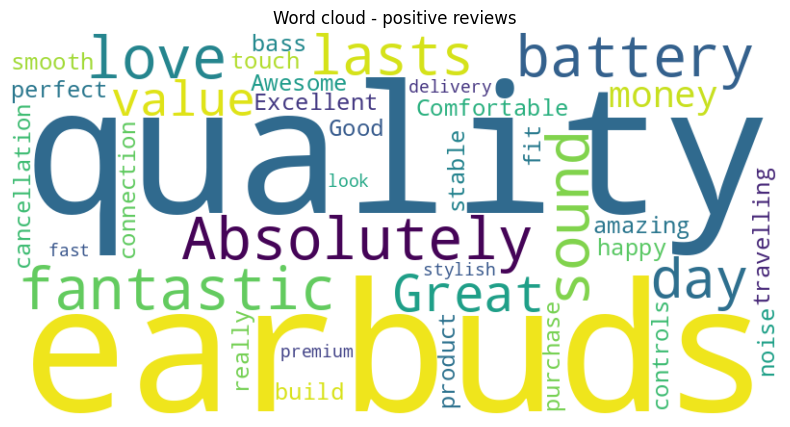

In [25]:
from wordcloud import WordCloud, STOPWORDS
pos_text = " ".join(result.loc[result["sentiment"]=="Positive","review"])
wc = WordCloud(width=800, height=400, background_color="white", stopwords=STOPWORDS).generate(pos_text)
plt.figure(figsize=(10,5)); plt.imshow(wc, interpolation="bilinear"); plt.axis("off")
plt.title("Word cloud - positive reviews"); plt.show()

## Q6. Text generation with Keras (LSTM)

In [26]:
data = ("Machine learning is changing the way we solve problems in the modern world. "
        "A model learns patterns from data and uses them to make predictions about new examples. "
        "Students who practice regularly can build powerful models with simple tools. "
        "Python makes it easy to write clean code and test ideas quickly. "
        "Libraries such as numpy and keras help us train neural networks without writing everything from scratch. "
        "Every experiment teaches something new about data and about ourselves. "
        "With patience and curiosity anyone can learn to build intelligent systems. "
        "The best way to learn is to keep trying, keep reading and keep building small projects every day.")
print("Word count:", len(data.split()))

Word count: 106


### 1. Tokenize using `Tokenizer()`

In [27]:
import numpy as np, tensorflow as tf
try:
    from keras.preprocessing.text import Tokenizer
except Exception:
    from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
tf.random.set_seed(42); np.random.seed(42)

tokenizer = Tokenizer()
tokenizer.fit_on_texts([data])
total_words = len(tokenizer.word_index) + 1
print("Vocabulary size:", total_words)
print(list(tokenizer.word_index.items())[:15])

I0000 00:00:1792658762.619562    1496 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1792658764.089440    1496 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Vocabulary size: 82
[('and', 1), ('to', 2), ('the', 3), ('about', 4), ('keep', 5), ('is', 6), ('way', 7), ('from', 8), ('data', 9), ('new', 10), ('can', 11), ('build', 12), ('with', 13), ('every', 14), ('learn', 15)]


### 2. Create input sequences and build the LSTM model

In [28]:
# n-gram sequences from each sentence: [w1 w2], [w1 w2 w3], ...
input_sequences = []
for line in data.replace(",", "").split("."):
    line = line.strip()
    if not line: continue
    token_list = tokenizer.texts_to_sequences([line])[0]
    for i in range(1, len(token_list)):
        input_sequences.append(token_list[:i+1])

max_len = max(len(s) for s in input_sequences)
input_sequences = pad_sequences(input_sequences, maxlen=max_len, padding="pre")
X, y = input_sequences[:, :-1], input_sequences[:, -1]
y = tf.keras.utils.to_categorical(y, num_classes=total_words)
print("Total sequences:", len(input_sequences), "| X shape:", X.shape, "| y shape:", y.shape)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
model = Sequential([
    Embedding(total_words, 32),
    LSTM(100),
    Dense(total_words, activation="softmax")
])
model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
model.build(input_shape=(None, max_len-1))
model.summary()

Total sequences: 98 | X shape: (98, 17) | y shape: (98, 82)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 17, 32)         │         2,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 100)            │        53,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 82)             │         8,282 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 64,106 (250.41 KB)

 Trainable params: 64,106 (250.41 KB)

 Non-trainable params: 0 (0.00 B)

### 3. Train the model and generate new text

Final training loss    : 0.5665
Final training accuracy: 0.9898


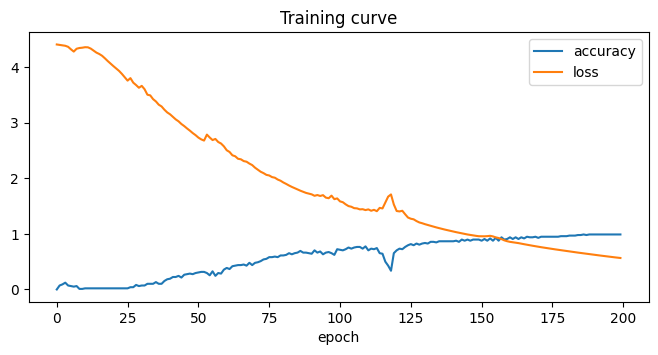

In [29]:
history = model.fit(X, y, epochs=200, verbose=0)
print("Final training loss    :", round(history.history["loss"][-1], 4))
print("Final training accuracy:", round(history.history["accuracy"][-1], 4))

plt.figure(figsize=(8,3.5))
plt.plot(history.history["accuracy"], label="accuracy"); plt.plot(history.history["loss"], label="loss")
plt.xlabel("epoch"); plt.legend(); plt.title("Training curve"); plt.show()

In [30]:
index_word = {v: k for k, v in tokenizer.word_index.items()}

def generate_text(seed_text, next_words=10):
    text = seed_text
    for _ in range(next_words):
        seq = tokenizer.texts_to_sequences([text])[0]
        seq = pad_sequences([seq], maxlen=max_len-1, padding="pre")
        pred = np.argmax(model.predict(seq, verbose=0), axis=-1)[0]
        text += " " + index_word.get(pred, "")
    return text

for seed in ["machine", "python", "students"]:
    print(f"Seed '{seed}' ->", generate_text(seed))

Seed 'machine' -> machine learning is changing the way we solve problems in the


Seed 'python' -> python makes it easy to write clean code and test ideas


Seed 'students' -> students who practice regularly can build powerful models with simple tools


**Note:** The training paragraph is very small (~100 words), so the LSTM mostly memorises the paragraph and the generated lines are close to the training sentences. With a larger corpus (and more epochs / a bigger model) the generated text would be more varied.